- 데이터 확인
- 중복 데이터 확인
- 이상 데이터 확인
- 손상된 알약을 가진 이미지가 있을까??
- 이미지마다 알약은 몇개씩 있을까??
- 

## 데이터 로드

JSON 라벨 파일 하나와 연결된 이미지 한 장을 읽어 확인한다.
JSON은 이미지 파일명, 알약 위치(bbox), 종류 ID를 담은 라벨 파일이다.
아래 셀을 위에서부터 실행하면 `img`에 RGB 이미지, `annotations`에 라벨이 저장된다.
전체 데이터 로드는 아니며, 다른 JSON에 나뉜 같은 이미지의 라벨은 아직 합치지 않는다.

In [ ]:
import json
from pathlib import Path

import cv2
import numpy as np

# 1. 프로젝트 최상위 폴더를 찾는다.
# 현재 폴더부터 상위 폴더까지 확인한다.
# src/config.py와 pyproject.toml이 함께 있는 곳을 프로젝트 루트로 판단한다.
PROJECT_ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "src" / "config.py").is_file() and (folder / "pyproject.toml").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("pill-bbox 프로젝트 안에서 노트북을 실행해 주세요.")

# 2. JSON 라벨 폴더와 이미지 폴더의 경로를 만든다.
annotation_dir = PROJECT_ROOT / "data" / "train_annotations"
image_dir = PROJECT_ROOT / "data" / "train_images"

# 3. 하위 폴더까지 탐색해서 JSON 파일 하나를 선택한다.
annotation_path = next(annotation_dir.rglob("*.json"), None)
if annotation_path is None:
    raise FileNotFoundError(f"JSON 라벨 파일이 없습니다: {annotation_dir}")

# 4. JSON 파일을 읽어 파이썬 딕셔너리로 바꾼다.
with annotation_path.open(encoding="utf-8") as file:
    data = json.load(file)

# 5. JSON에 기록된 첫 번째 이미지의 정보를 가져온다.
image_info = data["images"][0]

# 이미지 폴더 경로와 파일명을 합쳐 실제 이미지 경로를 만든다.
image_path = image_dir / image_info["file_name"]

# 6. 이미지 파일을 바이트 배열로 읽고, 이미지 배열로 변환한다.
# 이 방식은 한글이 포함된 경로에서도 이미지를 읽을 수 있게 한다.
img = cv2.imdecode(
    np.fromfile(image_path, dtype=np.uint8),
    cv2.IMREAD_COLOR,
)

# 파일을 이미지로 해석하지 못했다면 오류를 발생시킨다.
if img is None:
    raise ValueError(f"이미지를 읽을 수 없습니다: {image_path}")

# OpenCV 기본 색상 순서인 BGR을 RGB로 바꾼다.
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 7. JSON의 라벨 중 선택한 이미지에 연결된 것만 모은다.
annotations = [
    annotation for annotation in data["annotations"] if annotation["image_id"] == image_info["id"]
]

# 8. 읽은 결과를 확인한다.
print("이미지:", image_path.name)
print("이미지 크기:", img.shape)

for annotation in annotations:
    print("bbox:", annotation["bbox"])
    print("클래스:", annotation["category_id"])

## 데이터별 파일 수 확인

앞의 데이터 로드 셀을 먼저 실행한다. 하위 폴더를 포함해 이미지와 JSON 파일 수를 센다.
JSON은 라벨 파일이므로 이미지 수와 다를 수 있다. 파일 내용은 읽지 않는다.

In [ ]:
# 이미지 확장자는 대소문자 구분 없이 확인한다.
image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}

# 학습 이미지와 테스트 이미지 수를 각각 센다.
for folder_name in ("train_images", "test_images"):
    folder = PROJECT_ROOT / "data" / folder_name
    if not folder.is_dir():
        raise FileNotFoundError(f"데이터 폴더가 없습니다: {folder}")
    image_count = sum(
        1
        for path in folder.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    )
    print(f"{folder_name}: 이미지 {image_count:,}개")

# 라벨 JSON 수는 이미지 수와 구분해서 출력한다.
annotation_dir = PROJECT_ROOT / "data" / "train_annotations"
if not annotation_dir.is_dir():
    raise FileNotFoundError(f"라벨 폴더가 없습니다: {annotation_dir}")
annotation_count = sum(
    1 for path in annotation_dir.rglob("*") if path.is_file() and path.suffix.lower() == ".json"
)
print(f"train_annotations: JSON {annotation_count:,}개")

## 학습·테스트 이미지 구조 비교
앞의 데이터 로드 및 파일 수 확인 셀을 먼저 실행한다.
폴더, 파일명, 확장자, 해상도, 색상 모드를 비교한다. 결과 전체는 `image_structure`에 저장한다.
파일명 숫자의 의미는 데이터 명세로 확인하기 전까지 추정하지 않는다.

In [ ]:
from collections import Counter

import pandas as pd
from PIL import Image

# 전체 픽셀을 읽지 않고 이미지 헤더에서 크기와 색상 모드를 확인한다.
image_structure_rows = []
image_path_sets = {}
for split_name in ("train_images", "test_images"):
    split_dir = PROJECT_ROOT / "data" / split_name
    if not split_dir.is_dir():
        raise FileNotFoundError(f"이미지 폴더가 없습니다: {split_dir}")
    image_paths = sorted(
        path
        for path in split_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    )
    image_path_sets[split_name] = {path.name for path in image_paths}
    print(f"\n[{split_name}]")
    print(f"이미지 수: {len(image_paths):,}장")
    print(f"하위 폴더 수: {sum(path.is_dir() for path in split_dir.rglob('*'))}")
    print(
        "이미지 상위 폴더별 수:",
        dict(Counter(path.parent.relative_to(split_dir).as_posix() for path in image_paths)),
    )
    print("확장자별 수:", dict(Counter(path.suffix.lower() for path in image_paths)))
    print("파일명 예시:", [path.name for path in image_paths[:3]])
    print("숫자로만 된 파일명 수:", sum(path.stem.isdecimal() for path in image_paths))
    print("K-로 시작하는 파일명 수:", sum(path.stem.startswith("K-") for path in image_paths))

    for path in image_paths:
        row = {"구분": split_name, "파일명": path.relative_to(split_dir).as_posix()}
        try:
            with Image.open(path) as image:
                row.update({"너비": image.width, "높이": image.height, "색상 모드": image.mode})
        except (OSError, ValueError) as error:
            row["읽기 오류"] = str(error)
        image_structure_rows.append(row)

    split_rows = [row for row in image_structure_rows if row["구분"] == split_name]
    print(
        "해상도별 수 (너비, 높이):",
        dict(Counter((row["너비"], row["높이"]) for row in split_rows if "읽기 오류" not in row)),
    )
    print(
        "색상 모드별 수:",
        dict(Counter(row["색상 모드"] for row in split_rows if "읽기 오류" not in row)),
    )
    print("헤더 읽기 오류 수:", sum("읽기 오류" in row for row in split_rows))

image_structure = pd.DataFrame(image_structure_rows)
shared_image_names = image_path_sets["train_images"] & image_path_sets["test_images"]
print(f"\ntrain/test에서 동일한 파일명: {len(shared_image_names)}개")
print("파일명이 달라도 같은 사진일 수 있으므로 이미지 내용 중복 여부는 별도 검사해야 한다.")
print("헤더 확인만으로 이미지 전체의 손상 여부나 촬영 조건 차이를 판단할 수는 없다.")

## 사진별 JSON 및 라벨 수 확인
앞의 두 코드 셀을 먼저 실행한다. 전체 JSON을 읽어 파일명으로 묶는다.
라벨 수는 원본 annotation 항목 수이며 실제 알약 수와 같은지는 중복 검사가 필요하다.

In [ ]:
from collections import Counter

import pandas as pd

# 사진별 연결 관계를 확인하기 위해 이번에는 모든 JSON을 하나씩 읽는다.
# 이미지 픽셀은 읽지 않고, 파일명과 라벨 개수만 메모리에 저장한다.
image_json_paths = {}
image_label_counts = Counter()
json_count = 0
for annotation_path in annotation_dir.rglob("*"):
    if not annotation_path.is_file() or annotation_path.suffix.lower() != ".json":
        continue
    with annotation_path.open(encoding="utf-8") as file:
        annotation_data = json.load(file)
    json_count += 1
    image_names = {image["id"]: image["file_name"] for image in annotation_data["images"]}
    for image_name in image_names.values():
        image_json_paths.setdefault(image_name, set()).add(annotation_path)
    for label in annotation_data["annotations"]:
        # JSON 안의 image_id로 연결한다. 서로 다른 JSON의 ID를 직접 합치지 않는다.
        image_name = image_names[label["image_id"]]
        image_label_counts[image_name] += 1

# 실제 사진 파일과 JSON에서 참조한 파일을 비교한다.
image_dir = PROJECT_ROOT / "data" / "train_images"
actual_image_names = {
    path.relative_to(image_dir).as_posix()
    for path in image_dir.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
}
referenced_image_names = set(image_json_paths)
missing_image_names = referenced_image_names - actual_image_names
unlabeled_image_names = actual_image_names - referenced_image_names

# 파일명이 같으면 같은 이미지로 묶는다. 라벨 개수는 중복 제거 전 원본 항목 수다.
image_summary = pd.DataFrame(
    [
        {
            "이미지 파일명": image_name,
            "JSON 수": len(image_json_paths.get(image_name, set())),
            "라벨 수(중복 제거 전)": image_label_counts[image_name],
            "이미지 파일 존재": image_name in actual_image_names,
        }
        for image_name in sorted(actual_image_names | referenced_image_names)
    ],
    columns=["이미지 파일명", "JSON 수", "라벨 수(중복 제거 전)", "이미지 파일 존재"],
)

print(f"읽은 JSON: {json_count:,}개")
print(f"JSON에서 참조한 서로 다른 이미지: {len(referenced_image_names):,}장")
print(f"실제 학습 이미지: {len(actual_image_names):,}장")
print(f"JSON은 참조하지만 사진 파일이 없는 이미지: {len(missing_image_names):,}장")
print(f"연결된 JSON이 없는 사진: {len(unlabeled_image_names):,}장")
print(f"전체 라벨 항목: {sum(image_label_counts.values()):,}개 (중복 제거 전)")

print("\n이미지별 연결된 JSON 수 분포:")
print(image_summary["JSON 수"].value_counts().sort_index().rename_axis("JSON 수").to_string())
print("\n사진별 결과 예시 10개 (전체 결과는 image_summary에 저장):")
print(image_summary.head(10).to_string(index=False))

- train_annotations은 알약 종류뿐 아니라 사진 속 위치도 알려주는 정답 데이터
- 데이터는 사진 하나에 JSON이 여러 개 연결되어 있음
- 학습할 때는 같은 사진에 해당하는 라벨들을 모아줘야함

## 선택한 이미지에 연결된 JSON 모두 찾기
데이터 로드 셀을 먼저 실행한다. JSON 내부의 이미지 파일명을 기준으로 전체 라벨 폴더를 검색한다.
연결된 JSON 경로와 제품명, bbox를 출력하고 라벨을 모은다. 아래 시각화 셀은 모은 라벨 전체를 그린다.

In [ ]:
# 앞의 데이터 로드 셀에서 선택한 사진을 기준으로 찾는다.
# 다른 사진을 확인하려면 이 값을 train_images 안의 파일명으로 바꾼다.
target_image_name = image_info["file_name"]
matched_json_paths = []
all_annotations = []

# JSON 파일명 대신 내부 images의 file_name을 비교해야 정확하게 연결할 수 있다.
for json_path in sorted(annotation_dir.rglob("*.json")):
    with json_path.open(encoding="utf-8") as file:
        json_data = json.load(file)

    # image_id는 JSON마다 다를 수 있으므로 현재 JSON 안에서 찾아 연결한다.
    matched_image_ids = {
        image["id"] for image in json_data["images"] if image["file_name"] == target_image_name
    }
    if not matched_image_ids:
        continue

    matched_json_paths.append(json_path)
    matched_annotations = [
        label for label in json_data["annotations"] if label["image_id"] in matched_image_ids
    ]
    category_names = {
        category["id"]: category.get("name", "이름 없음") for category in json_data["categories"]
    }
    all_annotations.extend(matched_annotations)

    print(f"\nJSON: {json_path.relative_to(PROJECT_ROOT)}")
    for label in matched_annotations:
        category_id = label["category_id"]
        print(
            f"  종류 ID: {category_id}, "
            f"제품명: {category_names.get(category_id, '이름 없음')}, "
            f"bbox: {label['bbox']}"
        )

print(f"\n대상 이미지: {target_image_name}")
print(f"연결된 JSON: {len(matched_json_paths)}개")
print(f"모은 라벨: {len(all_annotations)}개 (중복 제거 전)")

# 아래 시각화 셀에서 선택한 사진과 모은 라벨 전체를 사용한다.
image_path = image_dir / target_image_name
img = cv2.imdecode(np.fromfile(image_path, dtype=np.uint8), cv2.IMREAD_COLOR)
if img is None:
    raise ValueError(f"이미지를 읽을 수 없습니다: {image_path}")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
annotations = all_annotations

- 이미지 하나에 JSON이 모두 연결되어 있다는 것을 확인하기 위함

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# JSON에 위치와 종류 정보가 있는지 확인한다.
for annotation in annotations:
    print("위치 정보:", annotation.get("bbox"))
    print("종류 ID:", annotation.get("category_id"))

# 사진 위에 bbox를 그린다.
fig, ax = plt.subplots(figsize=(8, 10))
ax.imshow(img)

for annotation in annotations:
    # bbox를 [왼쪽 x, 위쪽 y, 너비, 높이] 형식으로 해석한다.
    left, top, width, height = annotation["bbox"]

    ax.add_patch(
        Rectangle(
            (left, top),
            width,
            height,
            edgecolor="red",
            facecolor="none",
            linewidth=2,
        )
    )
    ax.text(
        left,
        top,
        str(annotation["category_id"]),
        color="white",
        backgroundcolor="red",
    )

ax.set_title("Annotation bbox")
ax.axis("off")
plt.show()

- 이미지 안에 있는 알약이 JSON이 다 연결되어 있다는걸 시각화를 통해 직접 확인

## JSON 및 라벨 중복 확인
데이터 로드 셀을 먼저 실행한다. 전체 JSON을 읽되 이미지는 읽지 않는다.
파일명 중복, 전체 내용 중복, 같은 이미지·종류·bbox의 반복을 구분한다.
bbox가 조금 다른 유사 라벨은 이 검사로 찾지 않는다. 반복 라벨은 삭제 전 다른 필드도 비교해야 한다.

In [ ]:
import hashlib
from collections import defaultdict

# 파일명이 같다는 이유만으로 중복으로 판단하지 않는다.
# 1. JSON 전체 내용이 같은지 검사한다 (공백과 객체 키 순서는 무시).
# 2. 같은 사진에 동일한 종류 ID와 bbox가 반복되는지 별도로 검사한다.
content_groups = defaultdict(list)
filename_groups = defaultdict(list)
label_groups = defaultdict(list)
checked_json_count = 0

for json_path in sorted(annotation_dir.rglob("*")):
    if not json_path.is_file() or json_path.suffix.lower() != ".json":
        continue
    with json_path.open(encoding="utf-8") as file:
        json_data = json.load(file)
    checked_json_count += 1
    relative_path = json_path.relative_to(PROJECT_ROOT).as_posix()
    filename_groups[json_path.name].append(relative_path)

    # 배열 순서와 모든 필드 값은 유지하여 전체 내용이 같은 파일만 묶는다.
    normalized_json = json.dumps(json_data, sort_keys=True, ensure_ascii=False)
    content_hash = hashlib.sha256(normalized_json.encode("utf-8")).hexdigest()
    content_groups[content_hash].append(relative_path)

    image_names = {image["id"]: image["file_name"] for image in json_data["images"]}
    for label_index, label in enumerate(json_data["annotations"]):
        # JSON마다 달라질 수 있는 라벨 ID 대신 사진·종류·위치로 비교한다.
        label_key = (
            image_names[label["image_id"]],
            label["category_id"],
            tuple(label["bbox"]),
        )
        label_groups[label_key].append(
            {"JSON 경로": relative_path, "라벨 인덱스": label_index, "라벨 ID": label.get("id")}
        )

# 이 변수에는 중복 그룹 전체를 보관한다. 원본 파일은 삭제하거나 수정하지 않는다.
duplicate_json_groups = [paths for paths in content_groups.values() if len(paths) > 1]
duplicate_label_groups = {key: entries for key, entries in label_groups.items() if len(entries) > 1}
same_filename_groups = {name: paths for name, paths in filename_groups.items() if len(paths) > 1}

print(f"검사한 JSON: {checked_json_count:,}개")
print(f"전체 내용이 같은 JSON: {len(duplicate_json_groups):,}그룹")
print(
    "그룹당 하나만 남겼을 때 중복 파일 수: "
    f"{sum(len(paths) - 1 for paths in duplicate_json_groups):,}개"
)
print(f"같은 사진·종류·bbox가 반복된 라벨: {len(duplicate_label_groups):,}그룹")
print(f"파일명만 같은 JSON: {len(same_filename_groups):,}그룹 (내용 중복과 별개)")

# 출력이 길어지지 않도록 각 검사 결과의 첫 5그룹만 보여 준다.
for group_number, paths in enumerate(duplicate_json_groups[:5], start=1):
    print(f"\n내용 중복 그룹 {group_number}:")
    for path in paths:
        print(f"  {path}")

for label_key, entries in list(duplicate_label_groups.items())[:5]:
    print(f"\n반복 라벨: 사진={label_key[0]}, 종류={label_key[1]}, bbox={label_key[2]}")
    for entry in entries:
        print(f"  {entry}")

- 파일명만 같은 JSON = 232그룹 : train_images와 크기가 같음
- JSON 763개가 232그룹안에 여러개씩 나눠서 들어있다고 생각할 수 있음

## 데이터 이상·누락·중복 검사
데이터 로드와 파일 수 확인 셀을 먼저 실행한다. 전체 이미지 픽셀과 JSON을 순차 검사한다.
손실은 파일 읽기 실패·연결 누락·필수 구조 오류로 확인하며, 원본 자료가 없으므로 원래 받을 파일의 유실 여부는 알 수 없다.
전체 오류는 `quality_report`, 동일 픽셀 그룹은 `exact_image_duplicates`, bbox 검토 후보는 `bbox_outlier_candidates`에 저장한다.
이미지 유사 중복과 실제 알약 라벨 누락은 자동 검사 범위에 포함되지 않는다. 원본 파일은 수정하지 않는다.

In [ ]:
import hashlib
import math
from collections import defaultdict

import pandas as pd
from PIL import Image

# 파일을 삭제하지 않고 검사 결과만 저장한다. 이미지는 한 장씩 읽고 메모리에서 해제한다.
quality_issues = []
pixel_groups = defaultdict(list)
perceptual_hashes = []
image_metadata = {}
split_image_counts = {}
for split_name in ("train_images", "test_images"):
    split_dir = PROJECT_ROOT / "data" / split_name
    if not split_dir.is_dir():
        raise FileNotFoundError(f"이미지 폴더가 없습니다: {split_dir}")
    image_paths = sorted(
        path
        for path in split_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    )
    split_image_counts[split_name] = len(image_paths)
    for image_path in image_paths:
        name = image_path.relative_to(split_dir).as_posix()
        image_metadata[(split_name, name)] = None
        try:
            # verify로 파일 형식을 검사한 뒤 다시 열어 전체 픽셀을 디코딩한다.
            with Image.open(image_path) as image:
                image.verify()
            with Image.open(image_path) as image:
                image.load()
                image_metadata[(split_name, name)] = image.size
                rgb = image.convert("RGB")
                digest = hashlib.sha256(rgb.tobytes()).hexdigest()
                # 64비트 차이 해시는 유사 후보용이다. 완전 중복 판정에는 사용하지 않는다.
                small = list(rgb.convert("L").resize((9, 8)).getdata())
                difference_hash = 0
                for row_index in range(8):
                    for column_index in range(8):
                        offset = row_index * 9 + column_index
                        difference_hash = (difference_hash << 1) | (
                            small[offset] > small[offset + 1]
                        )
                perceptual_hashes.append((split_name, name, difference_hash, digest))
                pixel_groups[(rgb.size, digest)].append((split_name, name))
        except (OSError, ValueError, SyntaxError) as error:
            quality_issues.append(
                {
                    "구분": split_name,
                    "파일": name,
                    "문제": "이미지 손상/읽기 실패",
                    "상세": str(error),
                }
            )
    print(f"{split_name}: 이미지 {len(image_paths):,}장 검사 완료", flush=True)

# 픽셀이 완전히 같은 사진만 중복으로 잡는다. 회전·재촬영·유사 사진 검사는 별도다.
exact_image_duplicates = [entries for entries in pixel_groups.values() if len(entries) > 1]
cross_split_duplicates = [
    entries for entries in exact_image_duplicates if len({split for split, name in entries}) > 1
]

annotation_dir = PROJECT_ROOT / "data" / "train_annotations"
if not annotation_dir.is_dir():
    raise FileNotFoundError(f"라벨 폴더가 없습니다: {annotation_dir}")
referenced_images = set()
labeled_images = set()
json_content_groups = defaultdict(list)
quality_label_groups = defaultdict(list)
bbox_rows = []
json_paths = sorted(
    path for path in annotation_dir.rglob("*") if path.is_file() and path.suffix.lower() == ".json"
)
for json_path in json_paths:
    relative_path = json_path.relative_to(PROJECT_ROOT).as_posix()
    try:
        with json_path.open(encoding="utf-8") as file:
            json_data = json.load(file)
        if not isinstance(json_data, dict) or any(
            not isinstance(json_data.get(key), list)
            for key in ("images", "annotations", "categories")
        ):
            raise ValueError("images, annotations, categories 배열이 필요합니다.")
        normalized = json.dumps(json_data, sort_keys=True, ensure_ascii=False)
        json_content_groups[hashlib.sha256(normalized.encode()).hexdigest()].append(relative_path)
        images_by_id = {}
        for image in json_data["images"]:
            if image["id"] in images_by_id:
                raise ValueError("JSON 내부의 이미지 ID가 중복됩니다.")
            images_by_id[image["id"]] = image
            name = image["file_name"]
            referenced_images.add(name)
            actual_size = image_metadata.get(("train_images", name))
            if ("train_images", name) not in image_metadata:
                quality_issues.append(
                    {
                        "구분": "annotation",
                        "파일": relative_path,
                        "문제": "연결된 이미지 파일 없음",
                        "상세": name,
                    }
                )
            elif actual_size is not None and actual_size != (image["width"], image["height"]):
                quality_issues.append(
                    {
                        "구분": "annotation",
                        "파일": relative_path,
                        "문제": "JSON과 실제 이미지 크기 불일치",
                        "상세": name,
                    }
                )
            if image["width"] <= 0 or image["height"] <= 0:
                raise ValueError("이미지 너비와 높이는 양수여야 합니다.")
        category_ids = {category["id"] for category in json_data["categories"]}
        for label_index, label in enumerate(json_data["annotations"]):
            # 오류가 있는 라벨 하나 때문에 나머지 라벨 검사가 중단되지 않게 한다.
            try:
                image = images_by_id[label["image_id"]]
                name = image["file_name"]
                labeled_images.add(name)
                if label["category_id"] not in category_ids:
                    raise ValueError("category_id에 해당하는 category가 없습니다.")
                bbox = label["bbox"]
                if (
                    not isinstance(bbox, list)
                    or len(bbox) != 4
                    or any(
                        isinstance(value, bool)
                        or not isinstance(value, (int, float))
                        or not math.isfinite(value)
                        for value in bbox
                    )
                ):
                    raise ValueError("bbox는 유한한 숫자 4개여야 합니다.")
                left, top, width, height = bbox
                if width <= 0 or height <= 0:
                    raise ValueError("bbox 너비 또는 높이가 0 이하입니다.")
                if (
                    left < 0
                    or top < 0
                    or left + width > image["width"]
                    or top + height > image["height"]
                ):
                    raise ValueError("bbox가 이미지 경계를 벗어납니다.")
                quality_label_groups[(name, label["category_id"], tuple(bbox))].append(
                    (relative_path, label_index)
                )
                bbox_rows.append(
                    {
                        "이미지": name,
                        "JSON": relative_path,
                        "종류 ID": label["category_id"],
                        "bbox": bbox,
                        "면적 비율": width * height / (image["width"] * image["height"]),
                    }
                )
            except (KeyError, TypeError, ValueError) as error:
                quality_issues.append(
                    {
                        "구분": "annotation",
                        "파일": relative_path,
                        "문제": "라벨 오류",
                        "상세": f"인덱스 {label_index}: {error}",
                    }
                )
    except (OSError, UnicodeError, ValueError, KeyError, TypeError) as error:
        quality_issues.append(
            {
                "구분": "annotation",
                "파일": relative_path,
                "문제": "JSON 파싱/구조 오류",
                "상세": str(error),
            }
        )

train_names = {name for split, name in image_metadata if split == "train_images"}
images_without_json = sorted(train_names - referenced_images)
images_without_labels = sorted(train_names - labeled_images)
duplicate_contents = [paths for paths in json_content_groups.values() if len(paths) > 1]
duplicate_labels = [entries for entries in quality_label_groups.values() if len(entries) > 1]
quality_report = pd.DataFrame(quality_issues, columns=["구분", "파일", "문제", "상세"])

# IQR 기준은 오류 판정이 아니라, 시각적으로 확인할 후보를 추리는 용도다.
bbox_quality = pd.DataFrame(bbox_rows, columns=["이미지", "JSON", "종류 ID", "bbox", "면적 비율"])
bbox_outlier_candidates = bbox_quality.copy()
if not bbox_quality.empty:
    lower_quartile = bbox_quality["면적 비율"].quantile(0.25)
    upper_quartile = bbox_quality["면적 비율"].quantile(0.75)
    spread = upper_quartile - lower_quartile
    bbox_outlier_candidates = bbox_quality[
        (bbox_quality["면적 비율"] < lower_quartile - 1.5 * spread)
        | (bbox_quality["면적 비율"] > upper_quartile + 1.5 * spread)
    ]

print(f"\nJSON 검사: {len(json_paths):,}개")
print("손상/누락/라벨 오류 유형별 수:")
print(
    quality_report["문제"].value_counts().to_string() if not quality_report.empty else "발견 없음"
)
print(f"연결된 JSON이 없는 학습 이미지: {len(images_without_json)}장")
print(f"annotation 항목이 연결되지 않은 학습 이미지: {len(images_without_labels)}장")
print(f"전체 내용이 같은 JSON: {len(duplicate_contents)}그룹")
print(f"같은 사진·종류·bbox의 정상 범위 라벨 중복: {len(duplicate_labels)}그룹")
for split_name in ("train_images", "test_images"):
    within_split = [
        entries
        for entries in exact_image_duplicates
        if sum(split == split_name for split, name in entries) > 1
    ]
    print(f"{split_name} 내부 픽셀 중복: {len(within_split)}그룹")
print(f"train/test 간 픽셀 중복: {len(cross_split_duplicates)}그룹")
print(f"bbox 면적 비율의 통계적 이상치 후보: {len(bbox_outlier_candidates)}개 (오류 확정 아님)")
if not quality_report.empty:
    print("\n오류 예시 10개:")
    print(quality_report.head(10).to_string(index=False))
if exact_image_duplicates:
    print("\n픽셀 중복 예시 5그룹:", exact_image_duplicates[:5])
if not bbox_outlier_candidates.empty:
    print("\n통계적 이상치 후보 예시 5개:")
    print(bbox_outlier_candidates.head(5).to_string(index=False))
print("\n테스트 정답 라벨이 제공되지 않아 테스트 라벨 누락은 판단하지 않는다.")
print("알약 라벨이 실제로 빠졌는지, bbox와 종류가 정확한지는 별도 시각 검토가 필요하다.")

- 확인해야할 데이터가 라벨 오류 1개, 이상치 후보 24개임 이것들을 확인

## 오류 및 이상치 후보 전체 시각화
데이터 이상·누락·중복 검사 셀을 먼저 실행한다. 면적 분포와 통계적 후보 전체를 표시한다.
빨간 사각형이 대상 알약을 잘 감싸는지, 다른 알약이나 배경을 과하게 포함하는지 확인한다.
경계 오류는 초록색 이미지 영역과 빨간색 bbox를 확장 좌표로 비교한다.
통계적 후보는 크기가 특이하다는 의미이며 오류로 확정하지 않는다.

In [ ]:
import math

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

# 먼저 '데이터 이상·누락·중복 검사' 셀을 실행한다.
# IQR 기준: 전체 유효 bbox 면적 비율의 중앙 50% 구간을 기준으로 후보를 찾는다.
review_rows = []
if not bbox_quality.empty:
    lower_limit = lower_quartile - 1.5 * spread
    upper_limit = upper_quartile + 1.5 * spread
    print(f"정상 참고 구간: 면적 비율 {lower_limit:.2%} ~ {upper_limit:.2%}")
    print("이 구간 밖이면 통계적 후보이며, 알약을 정확히 감싸면 정상 라벨일 수 있다.")

    # 전체 분포에 후보와 판정 기준선을 함께 표시한다.
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.hist(bbox_quality["면적 비율"] * 100, bins=30, color="steelblue")
    ax.axvline(lower_limit * 100, color="orange", linestyle="--", label="Lower IQR fence")
    ax.axvline(upper_limit * 100, color="red", linestyle="--", label="Upper IQR fence")
    ax.set(
        xlabel="BBox area / image area (%)", ylabel="Label count", title="BBox area distribution"
    )
    ax.legend()
    plt.tight_layout()
    plt.show()

    # 첫 몇 개만 고르지 않고 후보 전체를 4개씩 나누어 표시한다.
    candidates = bbox_outlier_candidates.to_dict("records")
    for start in range(0, len(candidates), 4):
        page = candidates[start : start + 4]
        fig, axes = plt.subplots(2, 2, figsize=(12, 15), squeeze=False)
        for offset, ax in enumerate(axes.flat):
            if offset >= len(page):
                ax.axis("off")
                continue
            row = page[offset]
            number = start + offset + 1
            with Image.open(PROJECT_ROOT / "data" / "train_images" / row["이미지"]) as image:
                ax.imshow(image.convert("RGB"))
                image_width, image_height = image.size
            left, top, width, height = row["bbox"]
            ax.add_patch(
                Rectangle((left, top), width, height, fill=False, color="red", linewidth=2)
            )
            ax.set_xlim(0, image_width)
            ax.set_ylim(image_height, 0)
            direction = "large" if row["면적 비율"] > upper_limit else "small"
            ax.set_title(
                f"Candidate {number}: unusually {direction} bbox\n"
                f"class={row['종류 ID']}, area={row['면적 비율']:.2%}\n"
                f"bbox={row['bbox']}",
                fontsize=10,
            )
            ax.set_xlabel(row["이미지"], fontsize=7)
            review_rows.append(
                {
                    "후보 번호": number,
                    "이미지": row["이미지"],
                    "종류 ID": row["종류 ID"],
                    "면적 비율(%)": round(row["면적 비율"] * 100, 2),
                    "상한(%)": round(upper_limit * 100, 2),
                    "이유": "면적 비율이 IQR 상한 초과"
                    if direction == "large"
                    else "면적 비율이 IQR 하한 미만",
                }
            )
        fig.suptitle("Red rectangle: candidate label (all candidates shown)")
        plt.tight_layout()
        plt.show()

# 경계 오류는 원래 사진과 좌표를 확장한 그림을 나란히 보여 준다.
# 사진 범위 밖의 bbox는 원래 사진 위에서는 보이지 않을 수 있다.
boundary_count = 0
for relative_json_path in quality_report.loc[
    quality_report["문제"] == "라벨 오류", "파일"
].unique():
    with (PROJECT_ROOT / relative_json_path).open(encoding="utf-8") as file:
        json_data = json.load(file)
    images_by_id = {image["id"]: image for image in json_data["images"]}
    for label in json_data["annotations"]:
        bbox = label.get("bbox")
        if (
            not isinstance(bbox, list)
            or len(bbox) != 4
            or not all(isinstance(value, (int, float)) and math.isfinite(value) for value in bbox)
        ):
            continue
        image_info = images_by_id.get(label.get("image_id"))
        if image_info is None:
            continue
        image_path = PROJECT_ROOT / "data" / "train_images" / image_info["file_name"]
        if not image_path.is_file():
            continue
        left, top, width, height = bbox
        with Image.open(image_path) as image:
            image_width, image_height = image.size
            if (
                width <= 0
                or height <= 0
                or not (
                    left < 0 or top < 0 or left + width > image_width or top + height > image_height
                )
            ):
                continue
            boundary_count += 1
            fig, axes = plt.subplots(1, 2, figsize=(14, 6))
            for ax in axes:
                ax.imshow(image.convert("RGB"))
                ax.add_patch(
                    Rectangle(
                        (0, 0), image_width, image_height, fill=False, color="lime", linewidth=2
                    )
                )
                ax.add_patch(
                    Rectangle((left, top), width, height, fill=False, color="red", linewidth=2)
                )
            axes[0].set(
                xlim=(0, image_width), ylim=(image_height, 0), title="Original image extent"
            )
            axes[1].set(
                xlim=(min(0, left) - 100, max(image_width, left + width) + 100),
                ylim=(max(image_height, top + height) + 100, min(0, top) - 100),
                title="Expanded coordinates: green=image, red=bbox",
            )
            fig.suptitle(f"Boundary error: class={label['category_id']}, bbox={bbox}")
            plt.tight_layout()
            plt.show()
        print(f"경계 오류 이미지: {image_info['file_name']}")
        print(f"이미지 범위: x=0~{image_width}, y=0~{image_height}")
        print(f"bbox 범위: x={left}~{left + width}, y={top}~{top + height}")

candidate_review = pd.DataFrame(review_rows)
print(f"통계적 후보 {len(review_rows)}개, 경계 오류 {boundary_count}개 시각화 완료")
if not candidate_review.empty:
    print("\n후보 번호별 판정 이유 (위 그림의 Candidate 번호와 대응):")
    print(candidate_review.to_string(index=False))
print("후보별 이유는 candidate_review에서 확인한다. 오류 좌표를 추정해 자동 수정하지 않는다.")

- 평균적인 면적 범위에 벗어나서(더 넓음) 이상치 후보로 등록된거같음
- 이미지 확인 결과 그냥 면적만 큰거같음 다른 이상이 없음
- 라벨 오류는 해결이 필요해보임

## 시각화 결과 해석

### 1. 좌표 오류 1개: 수정 검토가 필요한 라벨

- 이미지: `K-003351-016262-018357_0_2_0_2_75_000_200.png`
- 종류 ID: `18357`, bbox: `[6567, 625, 311, 315]`
- 사진 범위는 x=0~976, y=0~1280인데 박스의 x 범위가 6567~6878이므로 사진 밖에 있다.
- 왼쪽은 원본 사진, 오른쪽은 bbox까지 포함하도록 좌표를 확장한 그림이다. 초록색은 사진 경계, 빨간색은 라벨이다.
- 학습에 그대로 쓰면 잘못된 위치를 전달할 수 있다. 올바른 좌표를 사진·원본 자료와 대조한 후 수정하거나 해당 라벨의 제외를 검토한다. 6567의 의도된 값을 추측해서 바꾸지 않는다.

### 2. 면적 이상치 후보 24개: 오류 확정이 아닌 크기 검토 대상

- 면적 비율 = `(bbox 너비 × bbox 높이) / (이미지 너비 × 이미지 높이)`.
- 유효 bbox들의 면적 비율에서 Q1(25% 지점), Q3(75% 지점)을 구하고 `IQR = Q3 - Q1`로 계산한다.
- `Q1 - 1.5 × IQR`보다 작거나 `Q3 + 1.5 × IQR`보다 크면 후보로 표시한다. 이 기준은 정답의 허용 범위가 아니라 통계적 참고 기준이다.
- 현재 후보 24개는 모두 상한 약 **14.24%**보다 큰 bbox다. 그림의 `area`는 해당 bbox의 면적 비율이다.
- 빨간 박스가 큰 캡슐이나 정제를 감싸는 모습이므로, 시각 검토상 크기만으로 잘못된 라벨이라고 판단할 근거는 없다. 회전한 긴 알약은 축에 평행한 bbox 안에 배경이 더 들어갈 수 있다.
- 같은 종류의 알약이 크면 여러 사진이 함께 후보로 잡힐 수 있다. 종류별 크기 차이도 고려해야 한다.
- `Candidate 1`~`Candidate 24`를 아래 `candidate_review` 표의 후보 번호와 비교하면 사진·종류·면적 비율·선택 이유를 확인할 수 있다.

### 그림에서 확인할 것

1. 박스가 대상 알약 전체를 포함하는가?
2. 알약과 관계없는 위치나 다른 알약을 과도하게 포함하지 않는가?
3. 알약 일부가 박스 밖으로 잘려 있지 않은가?

여기서는 위치와 크기를 확인한다. 알약 종류의 정확성이나 다른 알약의 라벨 누락까지 검증한 것은 아니다. 원본 이미지와 JSON은 자동 수정하지 않는다.


## 기존 OpenCV로 bbox 수정 후보 제안
추가 패키지나 드래그 없이 이 사진의 색상 차이로 알약 윤곽을 찾는다.
1. 사진 확인 셀을 실행한다.
2. 윤곽 후보 셀을 실행해 빨간 박스가 대상 알약을 감싸는지 확인한다. 좌표는 자동으로 준비된다.
3. 다음 미리보기에서 확인한 후 저장 셀의 save_correction을 True로 바꿔 실행한다.
색상 임계값은 이 사진용이며 범용 검출 코드가 아니다. 기존 y·크기를 참고한 후보 순위도 틀릴 수 있다.
좌표 오류가 있다는 것만으로 정답 위치를 자동 확정할 수는 없다. 원본은 보존한다.

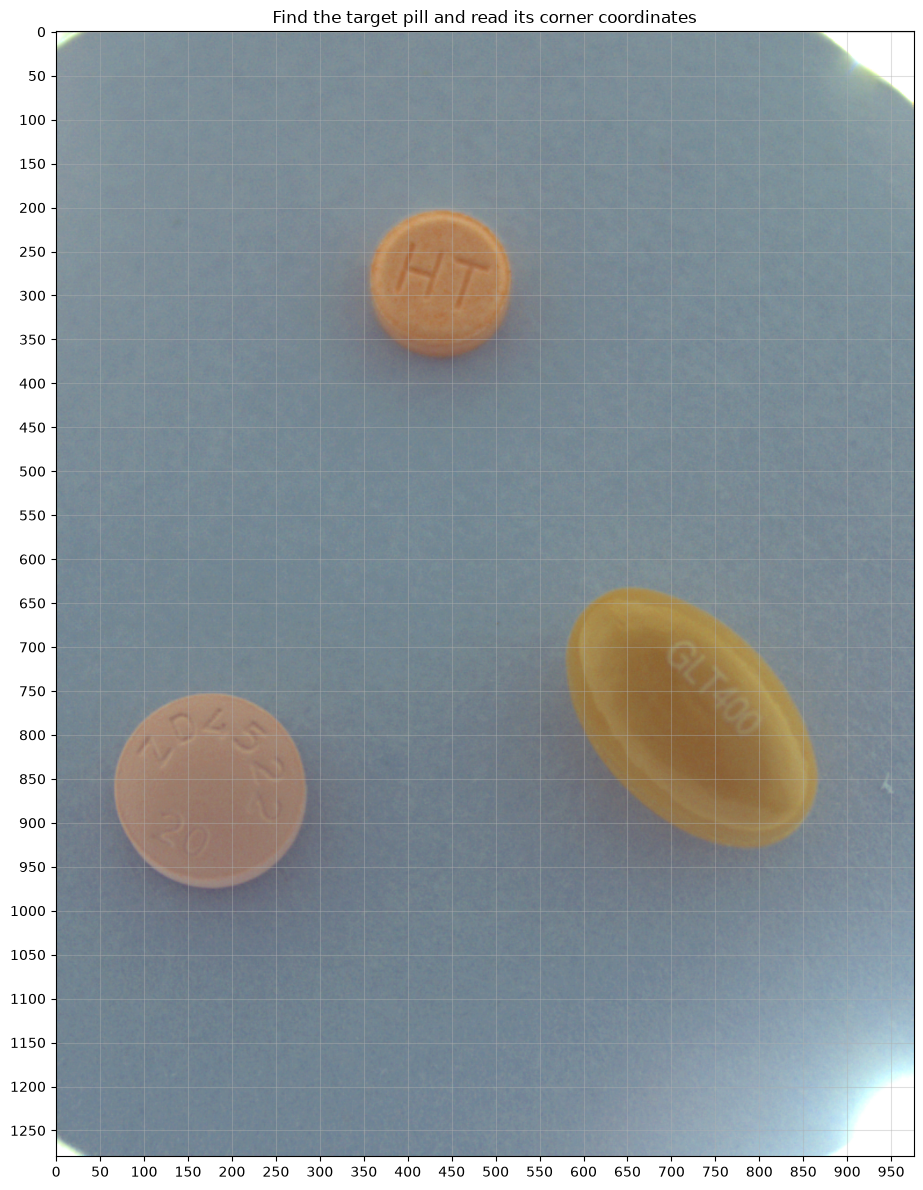

제품명: 종근당글리아티린연질캡슐(콜린알포세레이트) 
종류 ID: 18357
수정 전 bbox: [6567, 625, 311, 315]
사진의 실제 크기 (너비, 높이): (976, 1280)


In [71]:
%matplotlib inline

import copy
import hashlib
import json

import matplotlib.pyplot as plt
from PIL import Image

# 앞의 데이터 로드 셀에서 PROJECT_ROOT를 준비한다.
# 오류가 확인된 JSON만 읽는다. 다른 사진이나 라벨은 수정하지 않는다.
correction_source_path = (
    PROJECT_ROOT
    / "data/train_annotations/K-003351-016262-018357_json/K-018357"
    / "K-003351-016262-018357_0_2_0_2_75_000_200.json"
)
correction_source_bytes = correction_source_path.read_bytes()
correction_source_hash = hashlib.sha256(correction_source_bytes).hexdigest()
correction_data = json.loads(correction_source_bytes)
correction_targets = [
    label for label in correction_data["annotations"] if label["category_id"] == 18357
]
if len(correction_targets) != 1:
    raise ValueError("수정할 라벨을 하나로 확정할 수 없습니다.")
correction_target = correction_targets[0]
correction_image_info = next(
    image for image in correction_data["images"] if image["id"] == correction_target["image_id"]
)
correction_image_path = PROJECT_ROOT / "data/train_images" / correction_image_info["file_name"]
with Image.open(correction_image_path) as image:
    correction_image_size = image.size
    fig, ax = plt.subplots(figsize=(10, 12))
    ax.imshow(image.convert("RGB"))
    ax.set_xticks(range(0, image.width, 50))
    ax.set_yticks(range(0, image.height, 50))
    ax.grid(alpha=0.4)
    ax.set_title("Find the target pill and read its corner coordinates")
    plt.tight_layout()
    plt.show()

print("제품명:", correction_image_info.get("dl_name"))
print("종류 ID:", correction_target["category_id"])
print("수정 전 bbox:", correction_target["bbox"])
print("사진의 실제 크기 (너비, 높이):", correction_image_size)
correction_preview = None

후보 0: 모서리 좌표=(572, 625, 875, 937), 비교 점수=0.0457
후보 1: 모서리 좌표=(59, 746, 292, 977), 비교 점수=0.2752
후보 2: 모서리 좌표=(348, 195, 527, 380), 비교 점수=0.5954


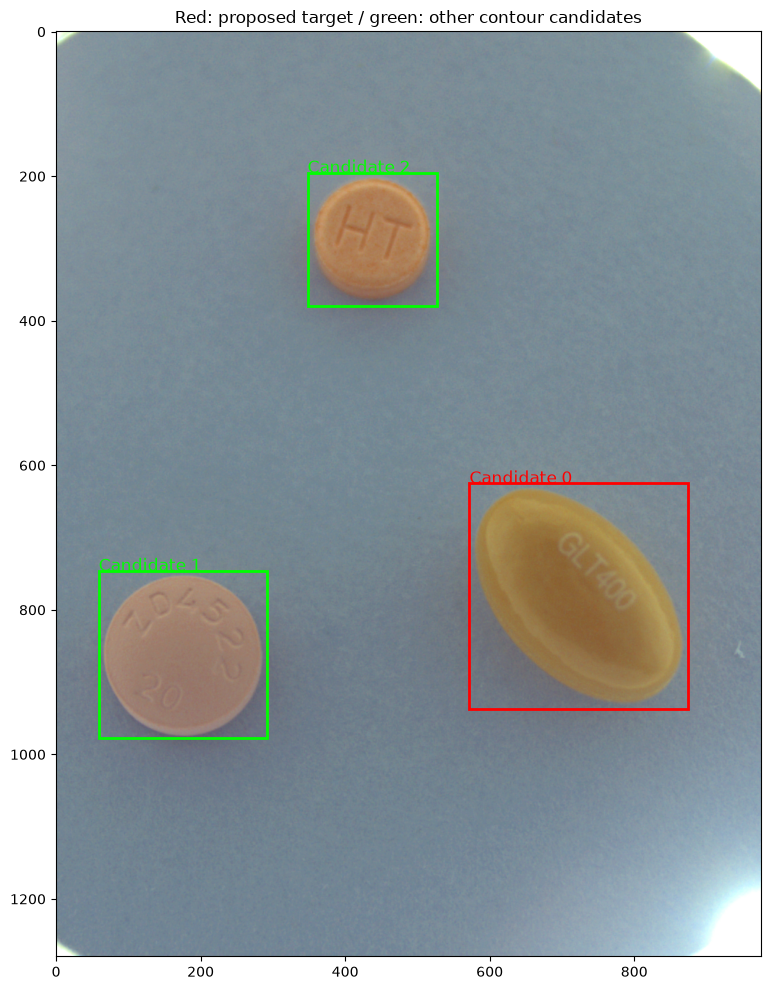

대상 제품명: 종근당글리아티린연질캡슐(콜린알포세레이트) 
제안 bbox: [572, 625, 303, 312]
빨간 박스가 대상 알약인지 확인하고 다음 미리보기 셀을 실행하세요.
아직 JSON은 저장하지 않았습니다. 경계가 부정확하면 저장하지 마세요.


In [72]:
import cv2
import numpy as np

# 이 사진의 푸른 배경과 갈색·노란색 알약을 분리하는 후보 생성 코드다.
# 모든 알약 데이터에 적용 가능한 검출 모델이 아니며 종류를 인식하는 코드도 아니다.
correction_preview = None
with Image.open(correction_image_path) as image:
    correction_rgb = np.array(image.convert("RGB"))
hsv = cv2.cvtColor(correction_rgb, cv2.COLOR_RGB2HSV)
pill_mask = cv2.inRange(hsv, np.array([0, 45, 35]), np.array([45, 255, 255]))
kernel = np.ones((5, 5), dtype=np.uint8)
pill_mask = cv2.morphologyEx(pill_mask, cv2.MORPH_CLOSE, kernel)
pill_mask = cv2.morphologyEx(pill_mask, cv2.MORPH_OPEN, kernel)
contours, _ = cv2.findContours(pill_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

image_width, image_height = correction_image_size
old_left, old_top, old_width, old_height = correction_target["bbox"]
contour_candidates = []
for contour in contours:
    if not 2000 < cv2.contourArea(contour) < image_width * image_height * 0.3:
        continue
    box_left, box_top, box_width, box_height = cv2.boundingRect(contour)
    # 잘못된 x좌표는 쓰지 않고, 기존 y와 크기가 비슷한 후보부터 제안한다.
    # 기존 y·크기까지 틀렸다면 이 순위도 틀릴 수 있으므로 사진으로 확인해야 한다.
    score = (
        abs(box_top - old_top) / image_height
        + abs(box_width - old_width) / image_width
        + abs(box_height - old_height) / image_height
    )
    # 반투명 가장자리가 마스크에서 빠질 수 있어 여유를 주고 미리보기로 확인한다.
    padding = 8
    candidate_left = max(0, box_left - padding)
    candidate_top = max(0, box_top - padding)
    candidate_right = min(image_width, box_left + box_width + padding)
    candidate_bottom = min(image_height, box_top + box_height + padding)
    contour_candidates.append(
        {"점수": score, "좌표": (candidate_left, candidate_top, candidate_right, candidate_bottom)}
    )
contour_candidates.sort(key=lambda candidate: candidate["점수"])

# 기본은 기존 y·크기에 가장 가까운 0번 후보다. 다른 알약이면 번호를 바꿔 재실행한다.
selected_candidate = 0
left = top = right = bottom = None
if not contour_candidates:
    print("알약 윤곽 후보를 찾지 못했습니다. 자동 수정하지 않습니다.")
else:
    if not 0 <= selected_candidate < len(contour_candidates):
        raise ValueError("선택한 후보 번호가 범위를 벗어났습니다.")
    fig, ax = plt.subplots(figsize=(8, 10))
    ax.imshow(correction_rgb)
    from matplotlib.patches import Rectangle

    for number, candidate in enumerate(contour_candidates):
        box_left, box_top, box_right, box_bottom = candidate["좌표"]
        color = "red" if number == selected_candidate else "lime"
        ax.add_patch(
            Rectangle(
                (box_left, box_top),
                box_right - box_left,
                box_bottom - box_top,
                fill=False,
                edgecolor=color,
                linewidth=2,
            )
        )
        ax.text(box_left, box_top, f"Candidate {number}", color=color, fontsize=12)
        print(f"후보 {number}: 모서리 좌표={candidate['좌표']}, 비교 점수={candidate['점수']:.4f}")
    ax.set_title("Red: proposed target / green: other contour candidates")
    plt.tight_layout()
    plt.show()
    left, top, right, bottom = contour_candidates[selected_candidate]["좌표"]
    print("대상 제품명:", correction_image_info.get("dl_name"))
    print("제안 bbox:", [left, top, right - left, bottom - top])
    print("빨간 박스가 대상 알약인지 확인하고 다음 미리보기 셀을 실행하세요.")
    print("아직 JSON은 저장하지 않았습니다. 경계가 부정확하면 저장하지 마세요.")

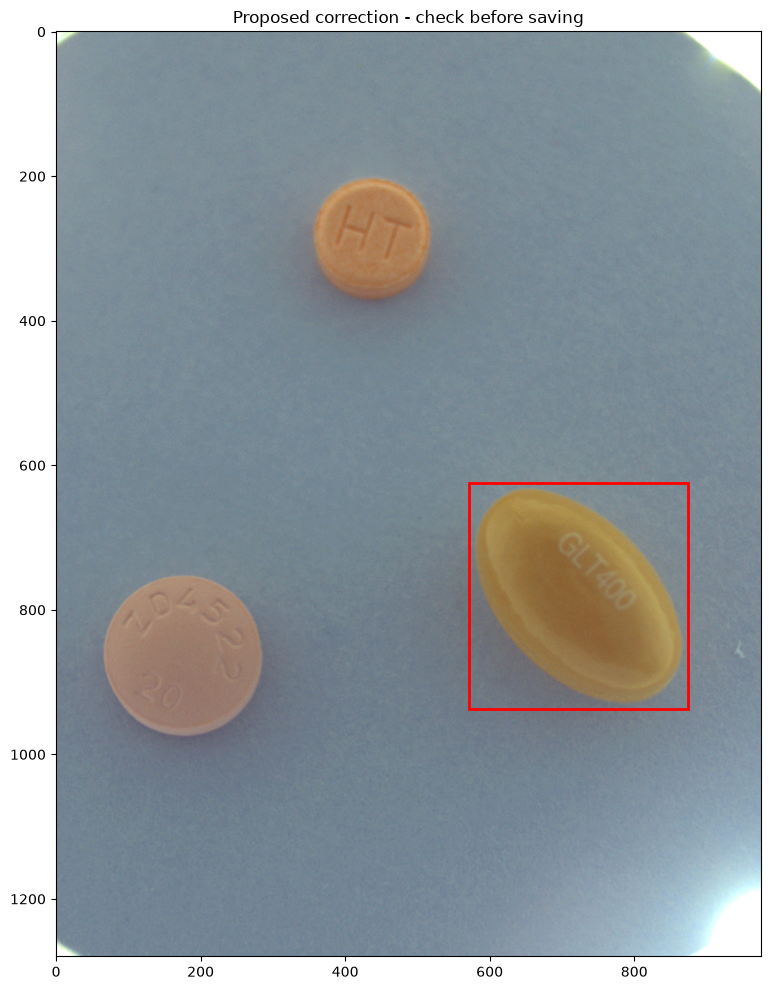

수정 전: [6567, 625, 311, 315]
수정 제안: [572, 625, 303, 312]
대상 알약을 정확히 감싸는지 확인한 뒤 다음 저장 셀을 실행해 주세요.


In [73]:
import math

from matplotlib.patches import Rectangle

# 위의 윤곽 후보 셀이 left, top, right, bottom을 자동으로 설정한다.
# 미리보기 실행 때마다 이전 결과를 초기화해 잘못된 좌표가 저장되지 않게 한다.
correction_preview = None
correction_coordinates = (left, top, right, bottom)
if any(value is None for value in correction_coordinates):
    print("먼저 위의 윤곽 후보 셀을 실행하고 대상 알약을 확인해 주세요.")
else:
    if any(
        isinstance(value, bool) or not isinstance(value, (int, float)) or not math.isfinite(value)
        for value in correction_coordinates
    ):
        raise ValueError("좌표는 유한한 숫자여야 합니다.")
    image_width, image_height = correction_image_size
    if not (0 <= left < right <= image_width and 0 <= top < bottom <= image_height):
        raise ValueError("좌표 순서 또는 이미지 범위를 확인해 주세요.")
    if correction_target.get("segmentation"):
        raise ValueError("segmentation 좌표도 함께 검토해야 하므로 자동 수정을 중단합니다.")

    # 원본 데이터는 그대로 두고 복사본에서 해당 라벨 하나만 바꾼다.
    proposed_data = copy.deepcopy(correction_data)
    proposed_targets = [
        label
        for label in proposed_data["annotations"]
        if label["id"] == correction_target["id"]
        and label["image_id"] == correction_target["image_id"]
    ]
    if len(proposed_targets) != 1:
        raise ValueError("라벨 ID와 이미지 ID가 유일하지 않습니다.")
    proposed_target = proposed_targets[0]
    proposed_target["bbox"] = [left, top, right - left, bottom - top]
    proposed_target["area"] = (right - left) * (bottom - top)

    with Image.open(correction_image_path) as image:
        fig, ax = plt.subplots(figsize=(8, 10))
        ax.imshow(image.convert("RGB"))
        ax.add_patch(
            Rectangle(
                (left, top), right - left, bottom - top, fill=False, edgecolor="red", linewidth=2
            )
        )
        ax.set_title("Proposed correction - check before saving")
        plt.tight_layout()
        plt.show()
    correction_preview = proposed_data
    preview_coordinates = correction_coordinates
    print("수정 전:", correction_target["bbox"])
    print("수정 제안:", proposed_target["bbox"])
    print("대상 알약을 정확히 감싸는지 확인한 뒤 다음 저장 셀을 실행해 주세요.")

In [75]:
from datetime import UTC, datetime

# 미리보기 확인 후에만 True로 바꾸고 이 셀을 실행한다.
# Run All을 해도 기본값 False에서는 저장되지 않는다.
save_correction = True

if not save_correction:
    print("저장하지 않았습니다. 좌표와 미리보기 확인 후 save_correction을 True로 바꾸세요.")
elif correction_preview is None:
    raise ValueError("유효한 좌표로 미리보기 셀을 먼저 실행해 주세요.")
else:
    if preview_coordinates != (left, top, right, bottom):
        raise ValueError("좌표가 바뀌었습니다. 미리보기를 다시 실행해 주세요.")
    if hashlib.sha256(correction_source_path.read_bytes()).hexdigest() != correction_source_hash:
        raise ValueError("원본 JSON이 바뀌었습니다. 사진 확인 셀부터 다시 실행해 주세요.")

    # 수정본과 수정 기록을 원본 라벨 폴더 밖에 저장한다.
    relative_path = correction_source_path.relative_to(PROJECT_ROOT / "data/train_annotations")
    correction_output_path = PROJECT_ROOT / "data/corrected_annotations" / relative_path
    correction_record_path = PROJECT_ROOT / "data/correction_records" / relative_path
    if correction_output_path.exists() or correction_record_path.exists():
        raise FileExistsError("기존 수정본 또는 수정 기록이 있습니다. 내용을 먼저 확인해 주세요.")
    correction_output_path.parent.mkdir(parents=True, exist_ok=True)
    correction_record_path.parent.mkdir(parents=True, exist_ok=True)

    correction_record = {
        "source": correction_source_path.relative_to(PROJECT_ROOT).as_posix(),
        "source_sha256": correction_source_hash,
        "label_id": correction_target["id"],
        "category_id": correction_target["category_id"],
        "before_bbox": correction_target["bbox"],
        "after_bbox": [left, top, right - left, bottom - top],
        "reason": "이미지 밖 bbox를 대상 알약의 위치를 확인하여 재지정",
        "recorded_at_utc": datetime.now(UTC).isoformat(),
    }
    with correction_output_path.open("x", encoding="utf-8") as file:
        json.dump(correction_preview, file, ensure_ascii=False, indent=4)
    with correction_record_path.open("x", encoding="utf-8") as file:
        json.dump(correction_record, file, ensure_ascii=False, indent=4)
    print("수정본:", correction_output_path)
    print("수정 기록:", correction_record_path)
    print("원본은 보존했습니다. 수정본을 학습 데이터에 반영하는 작업은 별도로 해야 합니다.")

수정본: /mnt/c/AI/test/pill-bbox/data/corrected_annotations/K-003351-016262-018357_json/K-018357/K-003351-016262-018357_0_2_0_2_75_000_200.json
수정 기록: /mnt/c/AI/test/pill-bbox/data/correction_records/K-003351-016262-018357_json/K-018357/K-003351-016262-018357_0_2_0_2_75_000_200.json
원본은 보존했습니다. 수정본을 학습 데이터에 반영하는 작업은 별도로 해야 합니다.


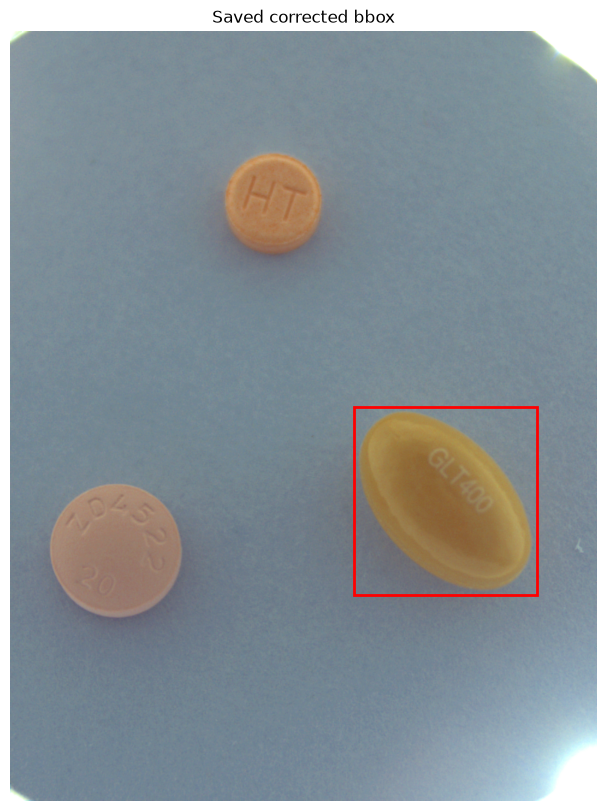

수정 전 bbox: [6567, 625, 311, 315]
저장된 bbox: [572, 625, 303, 312]


In [76]:
import json

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

# 저장된 수정본 JSON을 다시 읽는다.
with correction_output_path.open(encoding="utf-8") as file:
    corrected_data = json.load(file)

corrected_label = next(
    label
    for label in corrected_data["annotations"]
    if label["id"] == correction_target["id"]
    and label["image_id"] == correction_target["image_id"]
)

left, top, width, height = corrected_label["bbox"]

with Image.open(correction_image_path) as image:
    fig, ax = plt.subplots(figsize=(8, 10))
    ax.imshow(image.convert("RGB"))
    ax.add_patch(
        Rectangle(
            (left, top),
            width,
            height,
            fill=False,
            edgecolor="red",
            linewidth=2,
        )
    )
    ax.set_title("Saved corrected bbox")
    ax.axis("off")
    plt.show()

print("수정 전 bbox:", correction_target["bbox"])
print("저장된 bbox:", corrected_label["bbox"])

- 수정된 JSON bbox 시각화 확인